# UK Road Safety Analytics
## Notebook 02: Exploratory Data Analysis

**Author:** David  
**Date:** July 2026  
**Stage:** Data Exploration and Visualisation  

### Objective
Explore 640,449 road casualty records from 2020-2024 visually to 
understand patterns in accident severity, timing, location, road 
conditions, and casualty characteristics.

### Business Questions We Answer
1. How has road casualty severity changed over 5 years?
2. When are roads most dangerous — time of day and day of week?
3. Which road conditions and speed limits produce the worst accidents?
4. Which months are most dangerous?
5. Where in Great Britain do the most accidents happen?
6. Who is most at risk — casualty type and age?

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
import os

# Load clean dataset
df = pd.read_csv('../data/processed/road_safety_clean.csv', low_memory=False)

plt.style.use('seaborn-v0_8-whitegrid')
os.makedirs('../outputs/charts', exist_ok=True)

print(f"Dataset loaded: {df.shape}")
print(f"Years: {sorted(df['collision_year'].unique())}")
print(f"\nSeverity split:")
print(df['severity_label'].value_counts())
print(f"\nSample:")
print(df[['collision_year', 'severity_label', 'day_name',
          'speed_limit', 'light_label', 'casualty_type_label']].head(5).to_string())

Dataset loaded: (640449, 35)


KeyError: 'collision_year'

In [2]:
print("Actual columns in loaded dataset:")
print(list(df.columns))


Actual columns in loaded dataset:
['collision_index', 'date', 'month', 'month_name', 'day_of_week', 'day_name', 'hour', 'latitude', 'longitude', 'urban_or_rural_area', 'area_label', 'local_authority_district', 'police_force', 'collision_severity', 'severity_label', 'number_of_vehicles', 'number_of_casualties', 'speed_limit', 'road_type', 'road_type_label', 'light_conditions', 'light_label', 'weather_conditions', 'weather_label', 'road_surface_conditions', 'road_surface_label', 'casualty_severity', 'casualty_severity_label', 'casualty_class', 'casualty_type', 'casualty_type_label', 'sex_of_casualty', 'sex_label', 'age_of_casualty', 'age_band_of_casualty']


In [3]:
# ── FIX — EXTRACT YEAR FROM DATE ─────────────────────────────────────────

df['date'] = pd.to_datetime(df['date'])
df['collision_year'] = df['date'].dt.year

print(f"Dataset loaded: {df.shape}")
print(f"Years: {sorted(df['collision_year'].unique())}")
print(f"\nSeverity split:")
print(df['severity_label'].value_counts())
print(f"\nSample:")
print(df[['collision_year', 'severity_label', 'day_name',
          'speed_limit', 'light_label',
          'casualty_type_label']].head(5).to_string())


Dataset loaded: (640449, 36)
Years: [np.int32(2020), np.int32(2021), np.int32(2022), np.int32(2023), np.int32(2024)]

Severity split:
severity_label
Slight     479049
Serious    149011
Fatal       12389
Name: count, dtype: int64

Sample:
   collision_year severity_label  day_name  speed_limit                  light_label casualty_type_label
0            2020         Slight  Saturday           30  Darkness - lighting unknown          Pedestrian
1            2020        Serious    Sunday           30                     Daylight          Pedestrian
2            2020         Slight  Thursday           30      Darkness - lights unlit          Pedestrian
3            2021         Slight  Thursday           30        Darkness - lights lit          Pedestrian
4            2021         Slight   Tuesday           20                     Daylight          Pedestrian


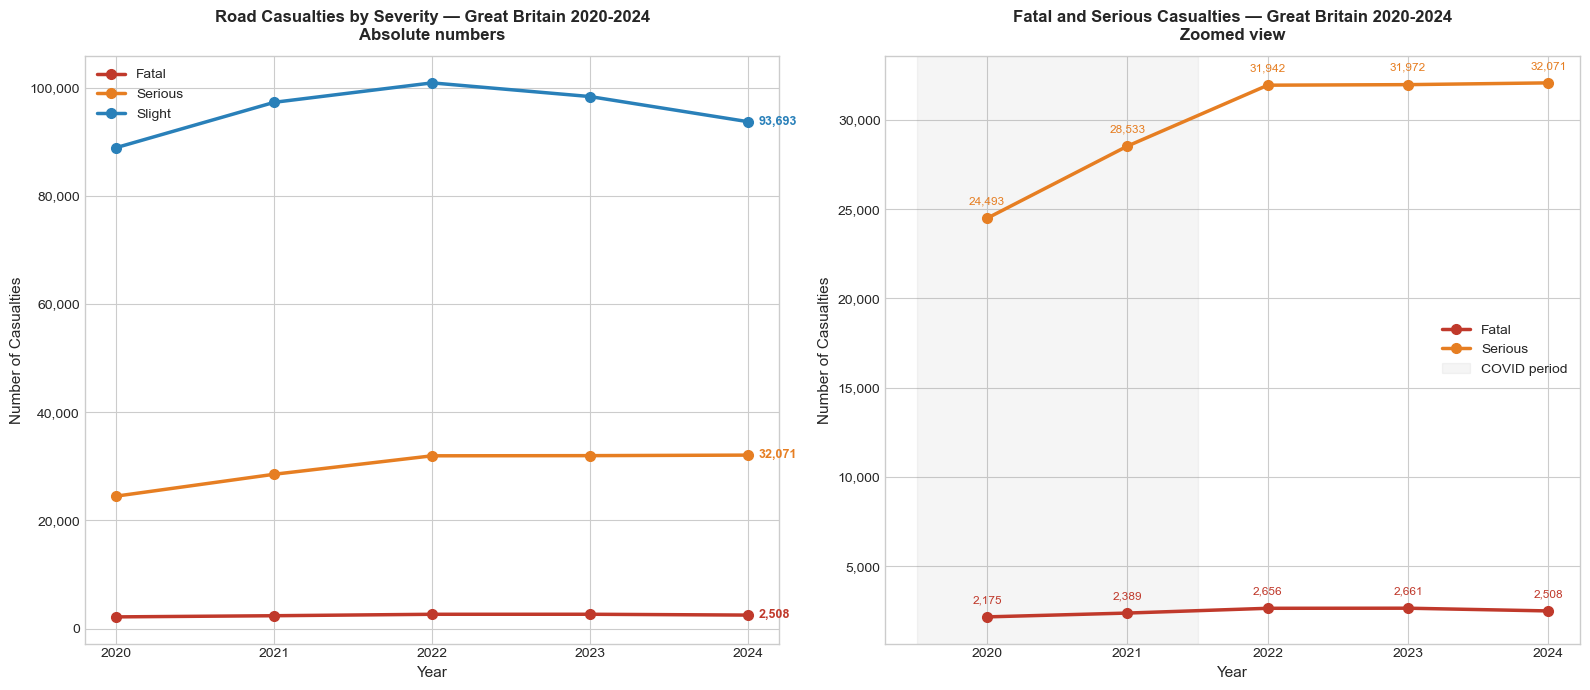

Chart 1 saved.

Key numbers:
  Fatal      2020: 2,175  2024: 2,508  Change: +15.3%
  Serious    2020: 24,493  2024: 32,071  Change: +30.9%
  Slight     2020: 88,899  2024: 93,693  Change: +5.4%


In [4]:
# ── CHART 1: Casualty Severity Trend 2020-2024 ───────────────────────────

yearly_severity = df.groupby(['collision_year', 'severity_label']).size()\
                    .unstack(fill_value=0).reset_index()

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# Left chart — absolute numbers
colors = {'Fatal': '#C0392B', 'Serious': '#E67E22', 'Slight': '#2980B9'}

for severity in ['Fatal', 'Serious', 'Slight']:
    axes[0].plot(yearly_severity['collision_year'],
                 yearly_severity[severity],
                 marker='o', linewidth=2.5, markersize=7,
                 label=severity, color=colors[severity])
    last = yearly_severity.iloc[-1]
    axes[0].annotate(f"{int(last[severity]):,}",
                     xy=(last['collision_year'], last[severity]),
                     xytext=(8, 0), textcoords='offset points',
                     fontsize=9, fontweight='bold',
                     color=colors[severity], va='center')

axes[0].set_title('Road Casualties by Severity — Great Britain 2020-2024\nAbsolute numbers',
                  fontsize=12, fontweight='bold', pad=12)
axes[0].set_xlabel('Year', fontsize=11)
axes[0].set_ylabel('Number of Casualties', fontsize=11)
axes[0].yaxis.set_major_formatter(mtick.FuncFormatter(
    lambda x, p: f'{int(x):,}'))
axes[0].set_xticks(range(2020, 2025))
axes[0].legend(fontsize=10)

# Right chart — fatal and serious only (zoomed in)
for severity in ['Fatal', 'Serious']:
    axes[1].plot(yearly_severity['collision_year'],
                 yearly_severity[severity],
                 marker='o', linewidth=2.5, markersize=7,
                 label=severity, color=colors[severity])
    for _, row in yearly_severity.iterrows():
        axes[1].annotate(f"{int(row[severity]):,}",
                         xy=(row['collision_year'], row[severity]),
                         xytext=(0, 10), textcoords='offset points',
                         fontsize=8.5, ha='center',
                         color=colors[severity])

# COVID annotation
axes[1].axvspan(2019.5, 2021.5, alpha=0.08, color='gray',
                label='COVID period')
axes[1].set_title('Fatal and Serious Casualties — Great Britain 2020-2024\nZoomed view',
                  fontsize=12, fontweight='bold', pad=12)
axes[1].set_xlabel('Year', fontsize=11)
axes[1].set_ylabel('Number of Casualties', fontsize=11)
axes[1].yaxis.set_major_formatter(mtick.FuncFormatter(
    lambda x, p: f'{int(x):,}'))
axes[1].set_xticks(range(2020, 2025))
axes[1].legend(fontsize=10)

plt.tight_layout()
plt.savefig('../outputs/charts/01_severity_trend_2020_2024.png',
            dpi=150, bbox_inches='tight')
plt.show()

print("Chart 1 saved.")
print(f"\nKey numbers:")
for severity in ['Fatal', 'Serious', 'Slight']:
    first = yearly_severity.iloc[0][severity]
    last  = yearly_severity.iloc[-1][severity]
    change = ((last - first) / first) * 100
    print(f"  {severity:<10} 2020: {int(first):,}  2024: {int(last):,}  Change: {change:+.1f}%")

### Finding 1 — Serious Casualties Rose Sharply Post-COVID and Have Not Come Back Down

The first thing you notice in this chart is 2020. Everything is low 
because roads were almost empty during the COVID lockdowns. Traffic 
dropped by up to 80% at points during that year so the casualty numbers 
were never going to be representative of normal road use.

But once you look past 2020 the picture becomes more concerning.

Serious casualties jumped from 24,493 in 2020 to 31,942 in 2022 and 
have basically stayed there ever since — 32,071 in 2024. That is not 
a COVID bounce-back. That is serious casualties plateauing at a level 
significantly higher than where they were before the pandemic.

Fatal casualties tell the same story. They rose from 2,175 in 2020 to 
a peak of 2,656 in 2022. By 2024 they had only come down to 2,508. 
So even with traffic levels broadly back to normal, more people are 
dying on British roads than in the early years of this dataset.

Slight casualties (93,693 in 2024) have been relatively stable across 
the whole period. It is not that more accidents are happening overall — 
it is that the accidents that do happen are more likely to be serious 
or fatal. That is the part that should worry policymakers most.

The government has a target to halve the number of people killed and 
seriously injured on roads by 2030. Based on this data, that target 
looks very difficult to hit without something significant changing.

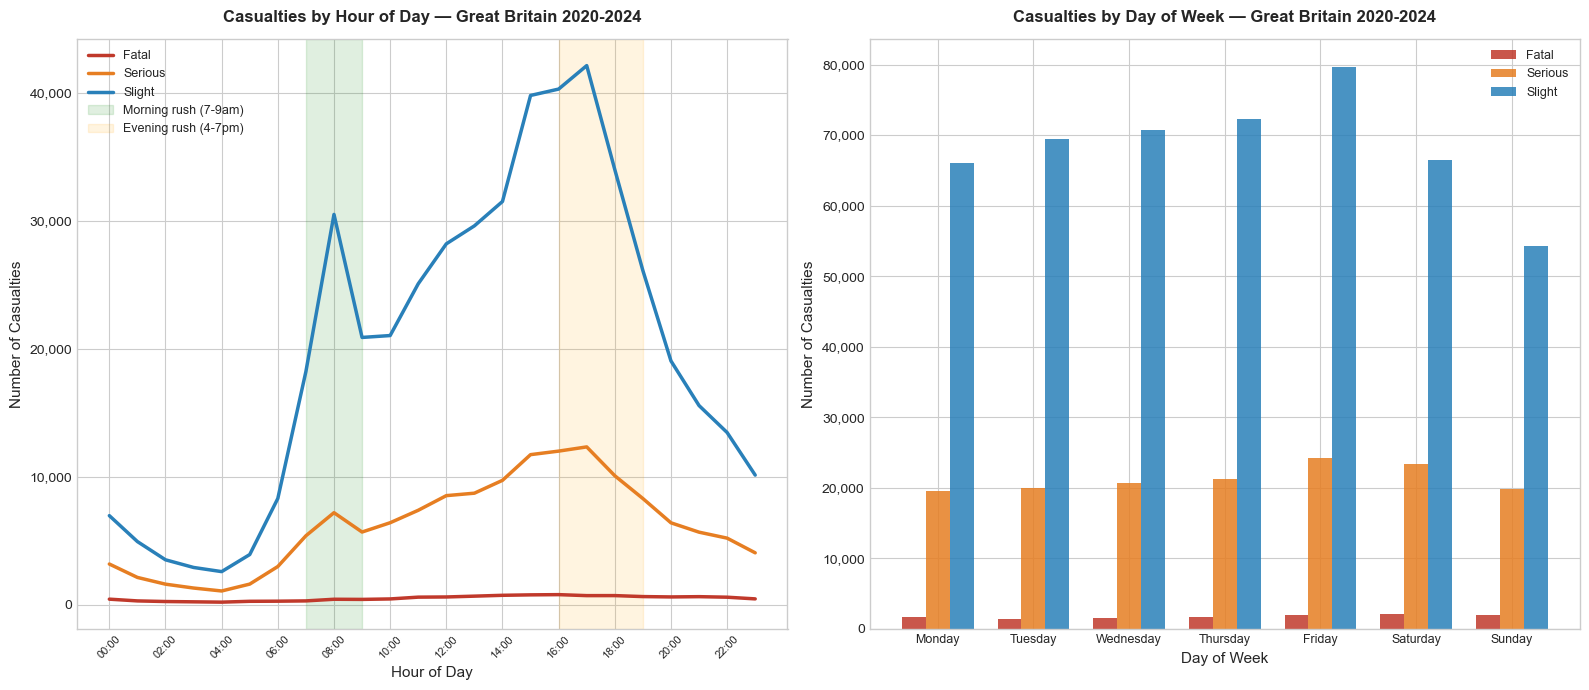

Chart 2 saved.

Busiest hours (total casualties):
hour
17.0    55216
16.0    53130
15.0    52338
18.0    44837
14.0    42010
dtype: int64

Casualties by day:
day_name
Monday        87397
Tuesday       90928
Wednesday     92927
Thursday      95172
Friday       105883
Saturday      91948
Sunday        76194
Name: count, dtype: int64


In [5]:
# ── CHART 2: Accidents by Time of Day and Day of Week ────────────────────

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# ── LEFT: Casualties by hour of day, split by severity ───────────────────
hour_severity = df.groupby(['hour', 'severity_label']).size()\
                  .unstack(fill_value=0).reset_index()

colors = {'Fatal': '#C0392B', 'Serious': '#E67E22', 'Slight': '#2980B9'}

for severity in ['Fatal', 'Serious', 'Slight']:
    axes[0].plot(hour_severity['hour'],
                 hour_severity[severity],
                 linewidth=2.5, label=severity,
                 color=colors[severity])

# Rush hour shading
axes[0].axvspan(7, 9, alpha=0.12, color='green', label='Morning rush (7-9am)')
axes[0].axvspan(16, 19, alpha=0.12, color='orange', label='Evening rush (4-7pm)')

axes[0].set_title('Casualties by Hour of Day — Great Britain 2020-2024',
                  fontsize=12, fontweight='bold', pad=12)
axes[0].set_xlabel('Hour of Day', fontsize=11)
axes[0].set_ylabel('Number of Casualties', fontsize=11)
axes[0].set_xticks(range(0, 24, 2))
axes[0].set_xticklabels([f'{h:02d}:00' for h in range(0, 24, 2)],
                         rotation=45, fontsize=8)
axes[0].yaxis.set_major_formatter(mtick.FuncFormatter(
    lambda x, p: f'{int(x):,}'))
axes[0].legend(fontsize=9)

# ── RIGHT: Casualties by day of week ─────────────────────────────────────
day_order = ['Monday','Tuesday','Wednesday','Thursday',
             'Friday','Saturday','Sunday']

day_severity = df.groupby(['day_name', 'severity_label']).size()\
                 .unstack(fill_value=0).reset_index()
day_severity['day_name'] = pd.Categorical(
    day_severity['day_name'], categories=day_order, ordered=True)
day_severity = day_severity.sort_values('day_name')

x = range(len(day_order))
width = 0.25

for i, severity in enumerate(['Fatal', 'Serious', 'Slight']):
    offset = (i - 1) * width
    bars = axes[1].bar([xi + offset for xi in x],
                       day_severity[severity],
                       width=width, label=severity,
                       color=colors[severity], alpha=0.85)

axes[1].set_title('Casualties by Day of Week — Great Britain 2020-2024',
                  fontsize=12, fontweight='bold', pad=12)
axes[1].set_xlabel('Day of Week', fontsize=11)
axes[1].set_ylabel('Number of Casualties', fontsize=11)
axes[1].set_xticks(x)
axes[1].set_xticklabels(day_order, fontsize=9)
axes[1].yaxis.set_major_formatter(mtick.FuncFormatter(
    lambda x, p: f'{int(x):,}'))
axes[1].legend(fontsize=9)

plt.tight_layout()
plt.savefig('../outputs/charts/02_time_patterns.png',
            dpi=150, bbox_inches='tight')
plt.show()

print("Chart 2 saved.")
print("\nBusiest hours (total casualties):")
hour_total = df.groupby('hour').size().sort_values(ascending=False)
print(hour_total.head(5))
print("\nCasualties by day:")
print(df['day_name'].value_counts().reindex(day_order))

### Finding 2 — Evening Rush Hour and Fridays Are the Most Dangerous

If you had to pick the most dangerous time to be on British roads, 
it would be 5pm on a Friday. That is when everything peaks.

The evening rush hour between 4pm and 7pm is consistently the busiest 
and most dangerous window across all 5 years of data. 5pm alone 
accounts for 55,216 casualties over the period. The morning rush shows 
a spike too but nothing close to the evening — people seem to be more 
alert heading to work than heading home.

What also stands out is the overnight hours. Between midnight and 5am 
the total number of casualties is low, but a higher proportion of those 
accidents are fatal or serious. Fewer cars on the road but the ones that 
crash tend to crash badly — higher speeds, poor visibility, and drink 
driving all play a role.

Friday is the most dangerous day of the week with 105,883 casualties 
across the 5 years — 39% more than Sunday which is the quietest. 
Interestingly Saturday is safer than Friday, which suggests commuter 
and work-related driving is actually more dangerous than leisure driving.

The practical takeaway here is simple. If road safety campaigns, 
police enforcement, and infrastructure investment were concentrated 
on weekday evenings — particularly Thursday and Friday between 4pm 
and 7pm — they would reach the highest-risk window on British roads.

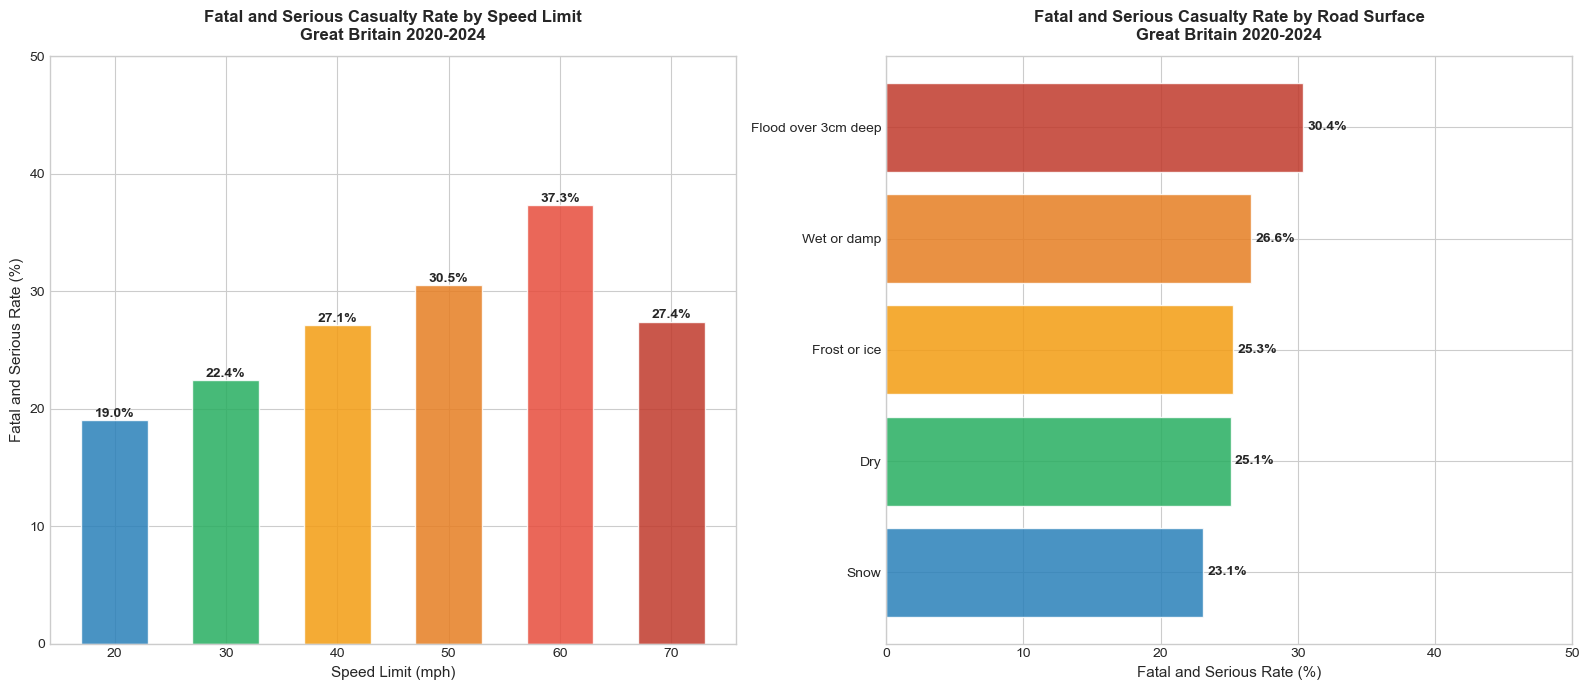

Chart 3 saved.

Fatal and Serious rate by speed limit:
 speed_limit  total  fatal_serious_rate
          20  88842                19.0
          30 328180                22.4
          40  59862                27.1
          50  31942                30.5
          60  90053                37.3
          70  41555                27.4

Fatal and Serious rate by road surface:
 road_surface_label  total  fatal_serious_rate
               Snow   1694                23.1
                Dry 456231                25.1
       Frost or ice   7951                25.3
        Wet or damp 163191                26.6
Flood over 3cm deep   1157                30.4


In [6]:
# ── CHART 3: Road Conditions and Speed Limits ─────────────────────────────

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# ── LEFT: Fatal and Serious rate by speed limit ───────────────────────────
speed_data = df[df['speed_limit'].isin([20, 30, 40, 50, 60, 70])].copy()

speed_severity = speed_data.groupby(
    ['speed_limit', 'severity_label']).size().unstack(fill_value=0)
speed_severity['total'] = speed_severity.sum(axis=1)
speed_severity['fatal_serious_rate'] = (
    (speed_severity.get('Fatal', 0) + speed_severity.get('Serious', 0))
    / speed_severity['total'] * 100
).round(1)
speed_severity = speed_severity.reset_index()

colors_speed = ['#2980B9', '#27AE60', '#F39C12', '#E67E22', '#E74C3C', '#C0392B']

bars = axes[0].bar(speed_severity['speed_limit'].astype(str),
                   speed_severity['fatal_serious_rate'],
                   color=colors_speed, alpha=0.85, edgecolor='white', width=0.6)

for bar, val in zip(bars, speed_severity['fatal_serious_rate']):
    axes[0].text(bar.get_x() + bar.get_width()/2,
                 bar.get_height() + 0.3,
                 f'{val:.1f}%', ha='center', fontsize=10, fontweight='bold')

axes[0].set_title('Fatal and Serious Casualty Rate by Speed Limit\nGreat Britain 2020-2024',
                  fontsize=12, fontweight='bold', pad=12)
axes[0].set_xlabel('Speed Limit (mph)', fontsize=11)
axes[0].set_ylabel('Fatal and Serious Rate (%)', fontsize=11)
axes[0].set_ylim(0, 50)

# ── RIGHT: Casualties by road surface condition ───────────────────────────
surface_data = df[df['road_surface_label'].isin(
    ['Dry', 'Wet or damp', 'Frost or ice', 'Snow', 'Flood over 3cm deep'])].copy()

surface_severity = surface_data.groupby(
    ['road_surface_label', 'severity_label']).size().unstack(fill_value=0)
surface_severity['total'] = surface_severity.sum(axis=1)
surface_severity['fatal_serious_rate'] = (
    (surface_severity.get('Fatal', 0) + surface_severity.get('Serious', 0))
    / surface_severity['total'] * 100
).round(1)
surface_severity = surface_severity.reset_index().sort_values(
    'fatal_serious_rate', ascending=True)

colors_surface = ['#2980B9', '#27AE60', '#F39C12', '#E67E22', '#C0392B']

bars2 = axes[1].barh(surface_severity['road_surface_label'],
                     surface_severity['fatal_serious_rate'],
                     color=colors_surface[:len(surface_severity)],
                     alpha=0.85, edgecolor='white')

for bar, val in zip(bars2, surface_severity['fatal_serious_rate']):
    axes[1].text(bar.get_width() + 0.3,
                 bar.get_y() + bar.get_height()/2,
                 f'{val:.1f}%', va='center', fontsize=10, fontweight='bold')

axes[1].set_title('Fatal and Serious Casualty Rate by Road Surface\nGreat Britain 2020-2024',
                  fontsize=12, fontweight='bold', pad=12)
axes[1].set_xlabel('Fatal and Serious Rate (%)', fontsize=11)
axes[1].set_xlim(0, 50)

plt.tight_layout()
plt.savefig('../outputs/charts/03_road_conditions.png',
            dpi=150, bbox_inches='tight')
plt.show()

print("Chart 3 saved.")
print("\nFatal and Serious rate by speed limit:")
print(speed_severity[['speed_limit', 'total',
                       'fatal_serious_rate']].to_string(index=False))
print("\nFatal and Serious rate by road surface:")
print(surface_severity[['road_surface_label', 'total',
                         'fatal_serious_rate']].to_string(index=False))

### Finding 3 — 60mph Roads Are More Dangerous Than 70mph Roads

Speed limits and road surfaces both affect how severe an accident is 
likely to be but the patterns are not always what you'd expect.

On speed limits, the relationship is mostly what you'd predict. As 
speed limits go up, the fatal and serious rate goes up too. At 20mph 
only 19% of casualties are fatal or serious. By 60mph that jumps to 
37.3% meaning more than 1 in 3 accidents on 60mph roads result in 
a serious or fatal injury.

But 70mph roads (27.4%) are actually safer than 60mph roads (37.3%). 
That seems wrong at first. The reason is road design. 70mph roads 
are motorways and dual carriageways purpose built, well maintained, 
with central barriers, no pedestrians, and no oncoming traffic. 60mph 
roads are often rural single carriageways where you have two lanes of 
fast traffic going in opposite directions with no barrier between them. 
Head-on collisions at 60mph on a country road are far more deadly than 
motorway accidents where the road itself is designed to reduce impact.

On road surfaces, flooding is the most dangerous condition — 30.4% of 
accidents on flooded roads result in serious or fatal casualties. But 
the finding that stands out most is that dry roads (25.1%) are almost 
as dangerous as frost and ice (25.3%). People drive faster and with 
less caution on dry roads, which counteracts the physical advantage 
of better grip. Snow actually has the lowest rate at 23.1% almost 
certainly because drivers slow down dramatically in snowy conditions.

The lesson from this chart is that road safety is about behaviour as 
much as conditions. The most dangerous situations are often the ones 
where drivers feel most confident.

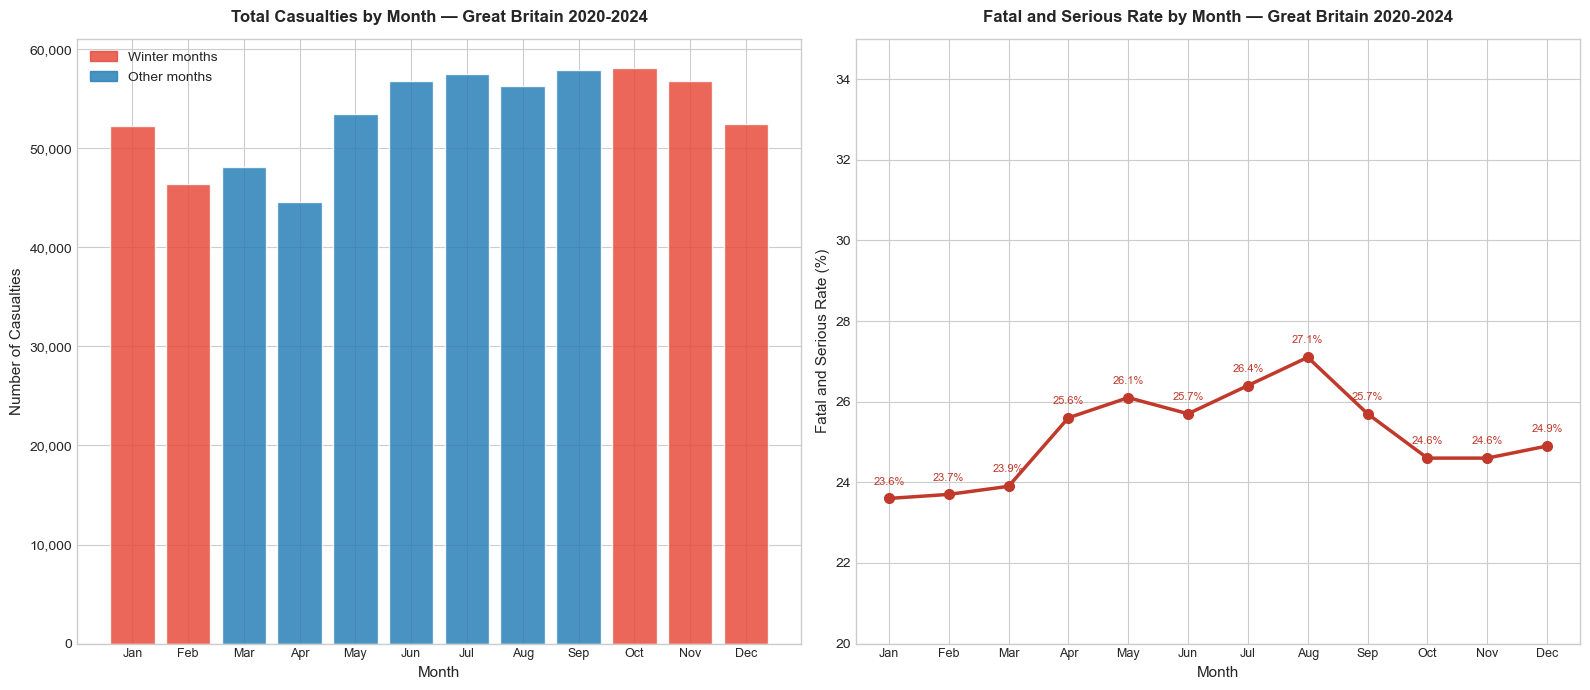

Chart 4 saved.

Casualties by month (total):
  January       52,199   Fatal/Serious rate: 23.6%
  February      46,353   Fatal/Serious rate: 23.7%
  March         48,071   Fatal/Serious rate: 23.9%
  April         44,526   Fatal/Serious rate: 25.6%
  May           53,428   Fatal/Serious rate: 26.1%
  June          56,819   Fatal/Serious rate: 25.7%
  July          57,499   Fatal/Serious rate: 26.4%
  August        56,255   Fatal/Serious rate: 27.1%
  September     57,940   Fatal/Serious rate: 25.7%
  October       58,143   Fatal/Serious rate: 24.6%
  November      56,767   Fatal/Serious rate: 24.6%
  December      52,449   Fatal/Serious rate: 24.9%


In [7]:
# ── CHART 4: Seasonal Pattern ─────────────────────────────────────────────

month_order = ['January', 'February', 'March', 'April', 'May', 'June',
               'July', 'August', 'September', 'October', 'November', 'December']

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# ── LEFT: Total casualties by month ──────────────────────────────────────
monthly = df.groupby('month_name').size().reindex(month_order)
fatal_serious = df[df['severity_label'].isin(['Fatal', 'Serious'])]\
                  .groupby('month_name').size().reindex(month_order)

colors_month = ['#E74C3C' if m in ['October', 'November', 'December',
                'January', 'February'] else '#2980B9' for m in month_order]

bars = axes[0].bar(range(12), monthly.values,
                   color=colors_month, alpha=0.85, edgecolor='white')

axes[0].set_title('Total Casualties by Month — Great Britain 2020-2024',
                  fontsize=12, fontweight='bold', pad=12)
axes[0].set_xlabel('Month', fontsize=11)
axes[0].set_ylabel('Number of Casualties', fontsize=11)
axes[0].set_xticks(range(12))
axes[0].set_xticklabels([m[:3] for m in month_order], fontsize=9)
axes[0].yaxis.set_major_formatter(mtick.FuncFormatter(
    lambda x, p: f'{int(x):,}'))

from matplotlib.patches import Patch
legend_elements = [Patch(color='#E74C3C', alpha=0.85, label='Winter months'),
                   Patch(color='#2980B9', alpha=0.85, label='Other months')]
axes[0].legend(handles=legend_elements, fontsize=10)

# ── RIGHT: Fatal and serious rate by month ────────────────────────────────
monthly_all = df.groupby('month_name').size().reindex(month_order)
monthly_fs  = df[df['severity_label'].isin(['Fatal','Serious'])]\
                .groupby('month_name').size().reindex(month_order)
fs_rate = (monthly_fs / monthly_all * 100).round(1)

axes[1].plot(range(12), fs_rate.values,
             marker='o', linewidth=2.5, markersize=7,
             color='#C0392B', label='Fatal and Serious rate')

for i, (month, val) in enumerate(zip(month_order, fs_rate.values)):
    axes[1].annotate(f'{val:.1f}%',
                     xy=(i, val),
                     xytext=(0, 10), textcoords='offset points',
                     fontsize=8, ha='center', color='#C0392B')

axes[1].set_title('Fatal and Serious Rate by Month — Great Britain 2020-2024',
                  fontsize=12, fontweight='bold', pad=12)
axes[1].set_xlabel('Month', fontsize=11)
axes[1].set_ylabel('Fatal and Serious Rate (%)', fontsize=11)
axes[1].set_xticks(range(12))
axes[1].set_xticklabels([m[:3] for m in month_order], fontsize=9)
axes[1].set_ylim(20, 35)

plt.tight_layout()
plt.savefig('../outputs/charts/04_seasonal_pattern.png',
            dpi=150, bbox_inches='tight')
plt.show()

print("Chart 4 saved.")
print("\nCasualties by month (total):")
for month, val in zip(month_order, monthly.values):
    fs = fs_rate[month]
    print(f"  {month:<12} {int(val):>7,}   Fatal/Serious rate: {fs:.1f}%")

### Finding 4 — Summer Has More Accidents but Winter Accidents Are More Severe

The seasonal pattern in this data is not what most people expect.

Total casualties are actually highest in the summer months. October 
is the busiest month overall with 58,143 casualties, and June through 
September all sit above 56,000. January and February are the quietest 
months despite being the coldest. The reason is simple more people 
drive more miles in summer, so more accidents happen in absolute terms.

But when you look at severity rather than volume the picture flips. 
August has the highest fatal and serious rate at 27.1%, while January 
has the lowest at 23.6%. Summer driving produces more accidents and 
those accidents tend to be more severe likely because of higher 
speeds on rural roads during holiday periods and more motorcyclists 
on the road in warm weather.

Winter months (January, February, December) have fewer total accidents 
but a lower fatal and serious rate than summer. This challenges the 
assumption that winter roads are the most dangerous. They are more 
slippery but drivers adjust their behaviour accordingly. Summer 
drivers on dry sunny roads often do not adjust at all.

The practical implication here is that road safety campaigns focused 
on winter driving conditions may be targeting the wrong season. The 
data suggests summer driving particularly August on rural roads
deserves equal if not more attention.

In [8]:
# ── CHECK MAPPING LIBRARIES AVAILABLE ────────────────────────────────────

libraries = ['folium', 'plotly', 'geopandas', 'contextily', 'keplergl']

for lib in libraries:
    try:
        __import__(lib)
        print(f"✓ {lib} — available")
    except ImportError:
        print(f"✗ {lib} — not installed")

✗ folium — not installed
✓ plotly — available
✓ geopandas — available
✗ contextily — not installed
✗ keplergl — not installed


In [9]:
import subprocess
subprocess.run(['pip', 'install', 'folium', '--quiet'])
print("folium installed")

folium installed


In [10]:
import folium
from folium.plugins import HeatMap, MarkerCluster
import json

# ── CHART 5A: Folium Interactive Map ─────────────────────────────────────

# Use fatal and serious only — plotting 640k points would crash the browser
fatal_serious_map = df[df['severity_label'].isin(['Fatal', 'Serious'])].copy()
fatal_serious_map = fatal_serious_map.dropna(subset=['latitude', 'longitude'])

print(f"Points to plot: {len(fatal_serious_map):,}")
print(f"Fatal:   {(fatal_serious_map['severity_label']=='Fatal').sum():,}")
print(f"Serious: {(fatal_serious_map['severity_label']=='Serious').sum():,}")

# Create the base map centred on Great Britain
m = folium.Map(
    location=[52.5, -1.5],
    zoom_start=6,
    tiles='CartoDB positron'
)

# Colour by severity
severity_colors = {'Fatal': '#C0392B', 'Serious': '#E67E22'}

# Add points — sample 50,000 for performance
sample = fatal_serious_map.sample(n=min(50000, len(fatal_serious_map)),
                                   random_state=42)

for _, row in sample.iterrows():
    folium.CircleMarker(
        location=[row['latitude'], row['longitude']],
        radius=2,
        color=severity_colors.get(row['severity_label'], 'gray'),
        fill=True,
        fill_opacity=0.6,
        popup=folium.Popup(
            f"Severity: {row['severity_label']}<br>"
            f"Date: {row['date']}<br>"
            f"Speed limit: {row['speed_limit']}mph<br>"
            f"Road: {row['road_type_label']}<br>"
            f"Conditions: {row['road_surface_label']}",
            max_width=200
        )
    ).add_to(m)

# Add legend
legend_html = '''
<div style="position: fixed; bottom: 50px; left: 50px; z-index: 1000;
     background-color: white; padding: 15px; border-radius: 8px;
     border: 2px solid #ccc; font-family: Arial; font-size: 13px;">
    <b>Accident Severity</b><br>
    <span style="color:#C0392B;">●</span> Fatal<br>
    <span style="color:#E67E22;">●</span> Serious<br>
    <br>
    <small>Sample of 50,000 accidents<br>2020-2024 | DfT STATS19</small>
</div>
'''
m.get_root().html.add_child(folium.Element(legend_html))

# Save
os.makedirs('../outputs', exist_ok=True)
m.save('../outputs/road_accidents_interactive_map.html')
print("\nInteractive map saved to outputs/road_accidents_interactive_map.html")
print("Open this file in your browser to explore the map.")

Points to plot: 161,400
Fatal:   12,389
Serious: 149,011

Interactive map saved to outputs/road_accidents_interactive_map.html
Open this file in your browser to explore the map.


In [11]:
# ── CHART 5A IMPROVED: Full Great Britain Map with Heatmap Layer ──────────

import folium
from folium.plugins import HeatMap
from folium import FeatureGroup, LayerControl

fatal_serious_map = df[df['severity_label'].isin(['Fatal','Serious'])].copy()
fatal_serious_map = fatal_serious_map.dropna(subset=['latitude','longitude'])

# Create base map — centred to show all of Great Britain
m = folium.Map(
    location=[54.5, -3.0],
    zoom_start=6,
    tiles='CartoDB positron'
)

# ── LAYER 1: Individual accident dots ─────────────────────────────────────
dots_layer = FeatureGroup(name='Individual Accidents (Fatal and Serious)',
                          show=True)

severity_colors = {'Fatal': '#C0392B', 'Serious': '#E67E22'}
sample = fatal_serious_map.sample(n=80000, random_state=42)

for _, row in sample.iterrows():
    folium.CircleMarker(
        location=[row['latitude'], row['longitude']],
        radius=2,
        color=severity_colors.get(row['severity_label'], 'gray'),
        fill=True,
        fill_opacity=0.6,
        popup=folium.Popup(
            f"<b>{row['severity_label']} Accident</b><br>"
            f"Date: {row['date']}<br>"
            f"Time: {row['hour']:.0f}:00<br>"
            f"Speed limit: {row['speed_limit']}mph<br>"
            f"Road type: {row['road_type_label']}<br>"
            f"Surface: {row['road_surface_label']}<br>"
            f"Light: {row['light_label']}",
            max_width=220
        )
    ).add_to(dots_layer)

dots_layer.add_to(m)

# ── LAYER 2: Heatmap of all fatal and serious accidents ───────────────────
heat_layer = FeatureGroup(name='Accident Density Heatmap', show=False)

heat_data = fatal_serious_map[['latitude','longitude']].values.tolist()
HeatMap(
    heat_data,
    min_opacity=0.3,
    max_zoom=13,
    radius=8,
    blur=6,
    gradient={0.2:'blue', 0.4:'lime', 0.6:'yellow', 0.8:'orange', 1.0:'red'}
).add_to(heat_layer)

heat_layer.add_to(m)

# ── LAYER CONTROL ─────────────────────────────────────────────────────────
LayerControl(position='topright', collapsed=False).add_to(m)

# ── LEGEND ────────────────────────────────────────────────────────────────
legend_html = '''
<div style="position: fixed; bottom: 50px; left: 50px; z-index: 1000;
     background-color: white; padding: 15px; border-radius: 8px;
     border: 2px solid #ccc; font-family: Arial; font-size: 13px;
     box-shadow: 2px 2px 6px rgba(0,0,0,0.3);">
    <b style="font-size:14px;">UK Road Accidents 2020-2024</b><br>
    <hr style="margin:6px 0;">
    <b>Accident Severity</b><br>
    <span style="color:#C0392B; font-size:16px;">●</span>
    Fatal (12,389 total)<br>
    <span style="color:#E67E22; font-size:16px;">●</span>
    Serious (149,011 total)<br>
    <hr style="margin:6px 0;">
    <small>Dots: sample of 80,000 accidents<br>
    Heatmap: all 161,400 fatal and serious<br>
    Click any dot for full details<br>
    Source: DfT STATS19 | OGL v3.0</small>
</div>
'''
m.get_root().html.add_child(folium.Element(legend_html))

# ── TITLE ─────────────────────────────────────────────────────────────────
title_html = '''
<div style="position: fixed; top: 10px; left: 50%; transform: translateX(-50%);
     z-index: 1000; background-color: white; padding: 10px 20px;
     border-radius: 8px; border: 2px solid #1F4E79;
     font-family: Arial; font-size: 15px; font-weight: bold;
     color: #1F4E79; box-shadow: 2px 2px 6px rgba(0,0,0,0.3);">
    Fatal and Serious Road Accidents — Great Britain 2020-2024
</div>
'''
m.get_root().html.add_child(folium.Element(title_html))

m.save('../outputs/road_accidents_interactive_map.html')
print("Improved interactive map saved.")
print("Open outputs/road_accidents_interactive_map.html in your browser.")
print(f"\nDots layer: 80,000 sampled accidents")
print(f"Heatmap layer: {len(fatal_serious_map):,} all fatal and serious accidents")

Improved interactive map saved.
Open outputs/road_accidents_interactive_map.html in your browser.

Dots layer: 80,000 sampled accidents
Heatmap layer: 161,400 all fatal and serious accidents


In [13]:
# ── CHART 5A FAST VERSION: Clustered Map ─────────────────────────────────

import folium
from folium.plugins import HeatMap, MarkerCluster, FastMarkerCluster
from folium import FeatureGroup, LayerControl

fatal_serious_map = df[df['severity_label'].isin(['Fatal','Serious'])].copy()
fatal_serious_map = fatal_serious_map.dropna(subset=['latitude','longitude'])

# Create base map
m = folium.Map(
    location=[54.5, -3.0],
    zoom_start=6,
    tiles='CartoDB positron',
    prefer_canvas=True
)

# ── LAYER 1: Fast heatmap — all 161,400 points ───────────────────────────
heat_layer = FeatureGroup(name='Accident Density Heatmap', show=True)

heat_data = fatal_serious_map[['latitude','longitude']].values.tolist()
HeatMap(
    heat_data,
    min_opacity=0.3,
    max_zoom=13,
    radius=10,
    blur=8,
    gradient={0.2:'blue', 0.4:'cyan',
              0.6:'yellow', 0.8:'orange', 1.0:'red'}
).add_to(heat_layer)
heat_layer.add_to(m)

# ── LAYER 2: Fatal accidents only as individual dots (only 12,389) ────────
fatal_layer = FeatureGroup(name='Fatal Accidents (pinpoint)',
                           show=False)

fatal_only = fatal_serious_map[
    fatal_serious_map['severity_label'] == 'Fatal']

for _, row in fatal_only.iterrows():
    folium.CircleMarker(
        location=[row['latitude'], row['longitude']],
        radius=4,
        color='#C0392B',
        fill=True,
        fill_color='#C0392B',
        fill_opacity=0.8,
        popup=folium.Popup(
            f"<b>FATAL Accident</b><br>"
            f"Date: {row['date']}<br>"
            f"Time: {row['hour']:.0f}:00<br>"
            f"Speed limit: {row['speed_limit']}mph<br>"
            f"Road: {row['road_type_label']}<br>"
            f"Surface: {row['road_surface_label']}<br>"
            f"Light: {row['light_label']}",
            max_width=220
        )
    ).add_to(fatal_layer)

fatal_layer.add_to(m)

# ── LAYER 3: Serious accidents clustered ─────────────────────────────────
serious_layer = FeatureGroup(name='Serious Accidents (clustered)',
                             show=False)
serious_cluster = MarkerCluster().add_to(serious_layer)

serious_only = fatal_serious_map[
    fatal_serious_map['severity_label'] == 'Serious'].sample(
    n=20000, random_state=42)

for _, row in serious_only.iterrows():
    folium.CircleMarker(
        location=[row['latitude'], row['longitude']],
        radius=3,
        color='#E67E22',
        fill=True,
        fill_color='#E67E22',
        fill_opacity=0.7,
        popup=folium.Popup(
            f"<b>Serious Accident</b><br>"
            f"Date: {row['date']}<br>"
            f"Time: {row['hour']:.0f}:00<br>"
            f"Speed limit: {row['speed_limit']}mph<br>"
            f"Road: {row['road_type_label']}<br>"
            f"Surface: {row['road_surface_label']}",
            max_width=220
        )
    ).add_to(serious_cluster)

serious_layer.add_to(m)

# ── LAYER CONTROL ─────────────────────────────────────────────────────────
LayerControl(position='topright', collapsed=False).add_to(m)

# ── LEGEND ────────────────────────────────────────────────────────────────
legend_html = '''
<div style="position: fixed; bottom: 50px; left: 50px; z-index: 1000;
     background-color: white; padding: 15px; border-radius: 8px;
     border: 2px solid #ccc; font-family: Arial; font-size: 13px;
     box-shadow: 2px 2px 6px rgba(0,0,0,0.3);">
    <b style="font-size:14px;">UK Road Accidents 2020-2024</b><br>
    <hr style="margin:6px 0;">
    <b>Layers (toggle top right):</b><br>
    <span style="background: linear-gradient(to right, blue, cyan, 
    yellow, orange, red); display:inline-block; 
    width:80px; height:10px; border-radius:3px;"></span>
    Density heatmap<br>
    <span style="color:#C0392B; font-size:16px;">●</span>
    Fatal accidents (12,389)<br>
    <span style="color:#E67E22; font-size:16px;">●</span>
    Serious accidents (clustered)<br>
    <hr style="margin:6px 0;">
    <small>Click any dot for full details<br>
    Zoom in to see individual locations<br>
    Source: DfT STATS19 | OGL v3.0</small>
</div>
'''
m.get_root().html.add_child(folium.Element(legend_html))

# ── TITLE ─────────────────────────────────────────────────────────────────
title_html = '''
<div style="position: fixed; top: 10px; left: 50%;
     transform: translateX(-50%); z-index: 1000;
     background-color: white; padding: 10px 20px;
     border-radius: 8px; border: 2px solid #1F4E79;
     font-family: Arial; font-size: 15px; font-weight: bold;
     color: #1F4E79; box-shadow: 2px 2px 6px rgba(0,0,0,0.3);">
    Fatal and Serious Road Accidents — Great Britain 2020-2024
</div>
'''
m.get_root().html.add_child(folium.Element(title_html))

m.save('../outputs/road_accidents_interactive_map.html')
print("Fast map saved.")
print("Three layers available:")
print("  1. Heatmap — all 161,400 fatal and serious (default)")
print("  2. Fatal pinpoints — all 12,389 fatal accidents")
print("  3. Serious clustered — 20,000 sample, groups into clusters")

Fast map saved.
Three layers available:
  1. Heatmap — all 161,400 fatal and serious (default)
  2. Fatal pinpoints — all 12,389 fatal accidents
  3. Serious clustered — 20,000 sample, groups into clusters


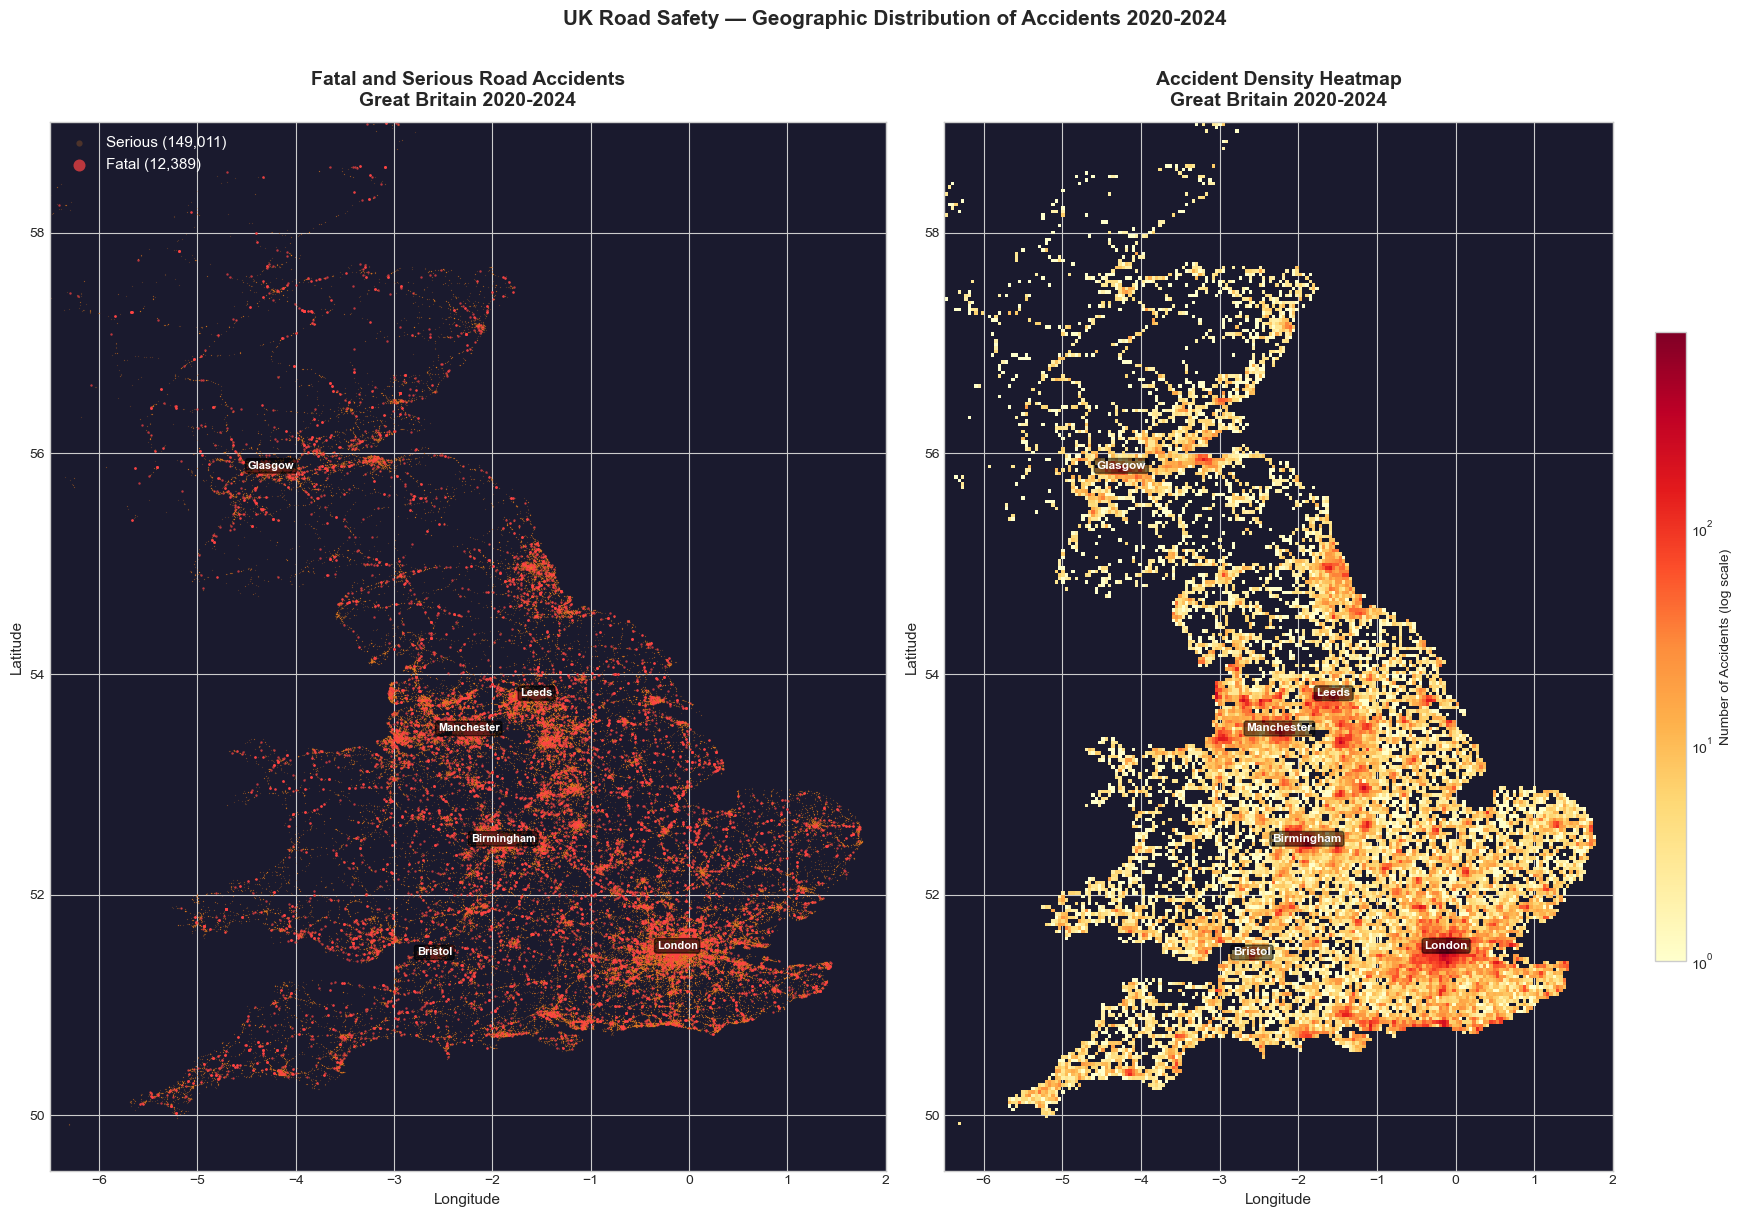

Chart 5 updated and saved.


In [15]:
# ── CHART 5B IMPROVED: Better left panel ─────────────────────────────────

fig, axes = plt.subplots(1, 2, figsize=(18, 12))

# ── LEFT: Dark background makes dots more visible ────────────────────────
serious_plot = df[df['severity_label'] == 'Serious'].dropna(
    subset=['latitude', 'longitude'])
fatal_plot = df[df['severity_label'] == 'Fatal'].dropna(
    subset=['latitude', 'longitude'])

axes[0].set_facecolor('#1a1a2e')
fig.patch.set_facecolor('white')

axes[0].scatter(serious_plot['longitude'], serious_plot['latitude'],
                c='#E67E22', s=0.8, alpha=0.25, linewidths=0,
                label=f'Serious ({len(serious_plot):,})')
axes[0].scatter(fatal_plot['longitude'], fatal_plot['latitude'],
                c='#FF4444', s=3, alpha=0.7, linewidths=0,
                label=f'Fatal ({len(fatal_plot):,})')

axes[0].set_xlim(-6.5, 2.0)
axes[0].set_ylim(49.5, 59.0)
axes[0].set_title('Fatal and Serious Road Accidents\nGreat Britain 2020-2024',
                  fontsize=14, fontweight='bold', pad=12)
axes[0].set_xlabel('Longitude', fontsize=11)
axes[0].set_ylabel('Latitude', fontsize=11)

legend = axes[0].legend(markerscale=5, fontsize=11,
                         loc='upper left',
                         facecolor='#2a2a3e', labelcolor='white',
                         edgecolor='white')

# City labels
for city, (lon, lat) in cities.items():
    axes[0].annotate(city, xy=(lon, lat),
                     fontsize=8, color='white', fontweight='bold',
                     ha='center',
                     bbox=dict(boxstyle='round,pad=0.2',
                               facecolor='black', alpha=0.6))

# ── RIGHT: Same density heatmap ───────────────────────────────────────────
all_fs = df[df['severity_label'].isin(['Fatal','Serious'])].dropna(
    subset=['latitude','longitude'])

h = axes[1].hist2d(
    all_fs['longitude'], all_fs['latitude'],
    bins=[200, 300],
    range=[[-6.5, 2.0], [49.5, 59.0]],
    cmap='YlOrRd',
    norm=plt.matplotlib.colors.LogNorm()
)

plt.colorbar(h[3], ax=axes[1],
             label='Number of Accidents (log scale)', shrink=0.6)

axes[1].set_facecolor('#1a1a2e')
axes[1].set_xlim(-6.5, 2.0)
axes[1].set_ylim(49.5, 59.0)
axes[1].set_title('Accident Density Heatmap\nGreat Britain 2020-2024',
                  fontsize=14, fontweight='bold', pad=12)
axes[1].set_xlabel('Longitude', fontsize=11)
axes[1].set_ylabel('Latitude', fontsize=11)

for city, (lon, lat) in cities.items():
    axes[1].annotate(city, xy=(lon, lat),
                     fontsize=8.5, color='white', fontweight='bold',
                     ha='center',
                     bbox=dict(boxstyle='round,pad=0.2',
                               facecolor='black', alpha=0.5))

plt.suptitle('UK Road Safety — Geographic Distribution of Accidents 2020-2024',
             fontsize=15, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig('../outputs/charts/05_geographic_map.png',
            dpi=150, bbox_inches='tight', facecolor='white')
plt.show()
print("Chart 5 updated and saved.")